#### 복습
- LLM = 대규모 언어 모델 (언 어!!)
- 에이전트 = 특정 작업을 수행하는 주체 (모델, 도구, 실행절차를 가진 주체...)
- Tool = 에이전트가 사용하는 도구 (예: 데이터베이스, API, 파일 시스템 등)
- State = 그래프에서 전체적으로 값을 기억하고 기록하는 역할
- Node = 그래프에서 상태를 나타내는 단위(내부적으론 함수로 나타냄)
- Edge = 그래프에서 노드 간의 관계를 나타내는 단위
- 노드와 에이전트의 차이점:
    - 노드: 그래프 안에서 실행단이 1개임
        - 노드는 llm이 들어있을수도 있고 단순한 함수일 수도 있음(안들어있을수도 있다는 말)
    - 에이전트: 목표를 가지고 실행할 수 있는 시스템이고 노드를 포함할 수 있음
        - 에이전트는 무조건 llm을 가지고 있어야 함
        - 즉, 에이전트는 여러 노드를 조합하여 복잡한 작업을 수행할 수 있음

![복습이미지](./images/ref/06_01.png)

___
```Markdown - 서론
이제는 시작이 있으면 llm에게 질문을 던지고 이 llm자체가 '검색이 필요한데?'하고 검색을 할건데
이 검색하는 툴 중에(Tavli...말고도 여러개 많음) 어떤 툴을 사용할지 llm이 판단해서 검색을 수행하게 될 것임

그럼 저 검색툴도 노드로 등록되어야 있어야 했는데
에이전트를 하나 만들어서 검색 엔진을 다 집어넣어두고
하나의 특정 전문 분야들끼리 묶어 에이전트를 만들고?

그 여러 에이전트들을 = 전문가 집단을 만들어 협업하게 할 수 있음!!
```

# **1. 멀티 에이전트**
- 단일 Agent가 조사, 분석, 작성, 검수까지 모두 맡으면 프롬프트가 복잡해지고, 실패 지점이나 책임을 구분하기 어려움!
- Multi Agent는 작업을 역할별로 나누고, 각 결과를 다음 담당자에게 전달함~!! (전문가 집단!)
    - [Multi Agent 종류]
    - Network: 동료 간 상호 위임이 가능한 연결 구조(거미줄처럼 연결되어있음)
    - Supervisor: 여러 담당자의 순서를 결정하는 중앙 관리자(나머지 에이전트를 컨트롤하는 심판 역할)
    - Hierarchical: 팀 안에 팀이 있는 계층적인 조직(Supervisor 확장판으로, 여러 계층의 관리자가 존재함)
    - Custom: 특정 요구사항에 맞게 설계된 맞춤형 구조(내가 만들고싶은 상태로 수정해서 만드는~~ | 위 3개가 기본적인거임)


### **1-1. 용어 설명**

#### 1-1-1. HandOff
- 현재 담당자가 다른 담당자에게 실행 제어권을 넘기는 것
- 그래프상에서 에이전트가 서로 다른 경우를 말하는데, 한 에이전트가 수행하던 작업을 다른 에이전트가 이어받아 수행하게 되는 상황을 의미함.

In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [11]:
# 에이전트 간 공유할 상태
class HandoffState(TypedDict, total=False):
    request: str        # 사용자 요청
    department: str     # 담당 부서
    answer: str         # 답변

# 요청 내용에 따라 담당 부서 결정
def triage(state: HandoffState):
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    return {"department": dept}

# 코딩 담당: 코드 예제 반환
def coding(state: HandoffState):
    return {"answer": f"[코딩 담당] {state['request']} > 예제: for x in [1, 2, 3]: print(x)"}

# 글쓰기 담당: 글 구성 안내 반환
def writing(state: HandoffState):
    return {"answer": f"[글쓰기 담당] {state['request']} > 도입/본문/마무리로 구성하세요"}

# 결정된 담당 부서로 이동할 경로 반환
def route_handoff(state: HandoffState):
    return state["department"]

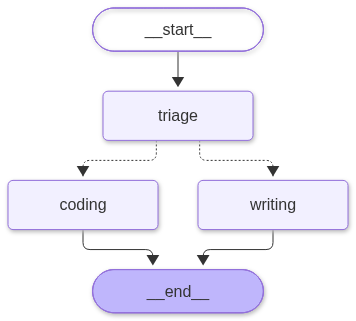

In [6]:
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

builder.add_edge(START, "triage")
builder.add_conditional_edges("triage", route_handoff, {"coding": "coding", "writing": "writing"})
builder.add_edge("coding", END)
builder.add_edge("writing", END)

handoff_graph = builder.compile()
handoff_graph

In [7]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    print(handoff_graph.invoke({"request": q}))

{'request': '파이썬 for문 설명해줘', 'department': 'coding', 'answer': '[코딩 담당] 파이썬 for문 설명해줘 > 예제: for x in [1, 2, 3]: print(x)'}
{'request': '감사 인사말을 작성해줘', 'department': 'writing', 'answer': '[글쓰기 담당] 감사 인사말을 작성해줘 > 도입/본문/마무리로 구성하세요'}


In [9]:
# stream_mode="updates": 과정이 보임
# 근데 지금은 단일 에이전트고 멀티에이전트로 바꾸려면 아래 코드셀 확인!
for update in handoff_graph.stream({"request": "파이썬 리스트 예제"}, stream_mode="updates"):
    print(update)

{'triage': {'department': 'coding'}}
{'coding': {'answer': '[코딩 담당] 파이썬 리스트 예제 > 예제: for x in [1, 2, 3]: print(x)'}}


In [13]:
from langchain_openai import ChatOpenAI
from langgraph.types import Command
from typing import TypedDict, Literal

In [ ]:
llm = ChatOpenAI(model="gpt-5.6-luna", temperature=0)

# ★★ 1. 분류 에이전트(노드 아님!!)
# Command: 실질적으로 Handoff를 실행하는건데 (이게 이제 에이전트들과 주고받기가 가능하게 해주는거임)
# Literal: 특정 값만 허용하도록 타입 지정
def triage(state: HandoffState) -> Command[Literal["coding", "writing"]]:
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    # goto: 이동할 에이전트 지정(명령어임) -> 다음에 실행할 노드 지정과 같은 말
    # update: 공유 상태(State)에 department 정보를 저장함
    return Command(update={"department": dept}, goto=dept)


# ★★ 2. 코딩 에이전트(노드 아님!!)
def coding(state: HandoffState):
    response = llm.invoke(
        f"당신은 파이썬 전문 강사입니다. 쉽게 설명하세요. \n질문: {state['request']}"
    )
    return {"answer": response.content}


# ★★ 3. 글쓰기 에이전트(노드 아님!!)
def writing(state: HandoffState):
    response = llm.invoke(
        f"당신은 전문 작가입니다. 자연스럽게 글을 작성하세요. \n요청: {state['request']}"
    )
    return {"answer": response.content}

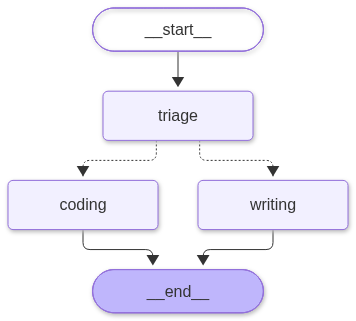

In [17]:
# 이제 위에걸로 그래프 구성!
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

# 멀티 에이전트에선 add_conditional_edges가 필요 없고, triage에서 바로 각 에이전트로 이동함(goto 사용)
builder.add_edge(START, "triage")
builder.add_edge("coding", END)
builder.add_edge("writing", END)

graph = builder.compile()
graph

In [18]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    result = graph.invoke({"request": q})
    print(f"\n질문: {q}")
    print(f"담당: {result['department']}")
    print(f"답변: {result['answer']}")


질문: 파이썬 for문 설명해줘
담당: coding
답변: 파이썬의 `for문`은 **여러 개의 데이터를 하나씩 꺼내 반복해서 처리할 때** 사용합니다.

## 1. 기본 형태

```python
for 변수 in 반복할_데이터:
    실행할_코드
```

예를 들어 리스트의 값을 하나씩 출력할 수 있습니다.

```python
fruits = ["사과", "바나나", "포도"]

for fruit in fruits:
    print(fruit)
```

실행 결과:

```text
사과
바나나
포도
```

동작 방식은 다음과 같습니다.

1. `fruits`에서 `"사과"`를 꺼내 `fruit`에 저장
2. `print(fruit)` 실행
3. `"바나나"`를 꺼내 다시 실행
4. `"포도"`까지 반복

---

## 2. 숫자를 반복할 때: `range()`

`range()`는 일정한 범위의 숫자를 만들어 줍니다.

```python
for number in range(5):
    print(number)
```

결과:

```text
0
1
2
3
4
```

주의할 점은 `range(5)`가 **0부터 4까지**라는 것입니다. 끝 숫자 5는 포함되지 않습니다.

### 1부터 5까지 출력

```python
for number in range(1, 6):
    print(number)
```

결과:

```text
1
2
3
4
5
```

### 2씩 증가

```python
for number in range(0, 10, 2):
    print(number)
```

결과:

```text
0
2
4
6
8
```

`range(시작, 끝, 증가값)` 형식입니다.

---

## 3. 문자열도 반복 가능

문자열의 글자를 하나씩 꺼낼 수도 있습니다.

```python
for character in "Python":
    print(character)
```

결과:

```text
P
y
t
h
o
n
```

---

## 4

![에이전트와 멀티에이전트 차이](./images/ref/06_02.png)